# Análise de Biologia ENEM 2024

In [2]:
import pandas as pd
import os
import glob

# CONFIGURAÇÃO DE CAMINHOS
caminho_base = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024"
caminho_dados_dir = os.path.join(caminho_base, "DADOS")

# Colunas essenciais ajustadas (adicionada NU_NOTA_CN para a correlação)
cols = [
    "SG_UF_PROVA", 
    "TP_PRESENCA_CN", 
    "CO_PROVA_CN", 
    "TX_RESPOSTAS_CN", 
    "TX_GABARITO_CN",
    "NU_NOTA_CN"  # Adicionada aqui para evitar reler o arquivo gigante depois
]

def detectar_arquivo_csv(pasta):
    """Detecta automaticamente o arquivo CSV principal dentro da pasta DADOS."""
    if not os.path.exists(pasta):
        print(f"ERRO: Pasta não encontrada -> '{pasta}'")
        return None
    
    arquivos = os.listdir(pasta)
    print(f"Arquivos encontrados em '{pasta}':")
    for arq in arquivos:
        print(f"  - {arq}")
    
    csvs = glob.glob(os.path.join(pasta, "*.csv"))
    
    if not csvs:
        print("\nERRO: Nenhum arquivo .csv encontrado na pasta DADOS.")
        print("Verifique se o arquivo ainda está compactado (.zip ou .rar).")
        return None
    
    # Prioriza o arquivo de resultados/participantes pelo tamanho
    csvs.sort(key=os.path.getsize, reverse=True)
    candidato = [c for c in csvs if "RESULTADOS" in os.path.basename(c).upper() or "MICRODADOS" in os.path.basename(c).upper()]
    arquivo_escolhido = candidato[0] if candidato else csvs[0]
    
    print(f"\nArquivo CSV detectado para os participantes: {os.path.basename(arquivo_escolhido)}")
    return arquivo_escolhido


def carregar_dados_biologia(caminho):
    print(f"\n--- Acessando arquivo de microdados: {caminho} ---")
    
    try:
        chunks = pd.read_csv(
            caminho, 
            sep=";", 
            encoding="latin1", 
            usecols=cols, 
            chunksize=500000
        )
        
        lista_processada = []
        
        for i, chunk in enumerate(chunks):
            # Filtra apenas quem esteve presente em Ciências da Natureza
            presentes = chunk[chunk["TP_PRESENCA_CN"] == 1].copy()
            lista_processada.append(presentes)
            print(f"  Bloco {i+1} processado — {len(presentes):,} participantes presentes.")
            
        df_final = pd.concat(lista_processada, ignore_index=True)
        
        print("\n--- Carregamento Concluído com Sucesso ---")
        print(f"Total de registros válidos carregados: {len(df_final):,}")
        return df_final

    except ValueError as e:
        print(f"\nERRO de coluna: {e}")
        print("Verificando colunas disponíveis no arquivo...")
        df_amostra = pd.read_csv(caminho, sep=";", encoding="latin1", nrows=5)
        print("Colunas disponíveis:", df_amostra.columns.tolist())
        return None

    except Exception as e:
        print(f"\nErro inesperado: {e}")
        return None


if __name__ == "__main__":
    caminho_csv = detectar_arquivo_csv(caminho_dados_dir)
    
    if caminho_csv is not None:
        df_biologia = carregar_dados_biologia(caminho_csv)
        
        if df_biologia is not None:
            print("\nEstrutura dos dados carregados:")
            print(df_biologia.head())

Arquivos encontrados em 'G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS':
  - acerto_biologia_por_uf.csv
  - acerto_biologia_por_uf_habilidade.csv
  - aprofundamento_h01_por_uf.png
  - gap_regional_habilidades_biologia.csv
  - heatmap_biologia_uf_habilidade.png
  - ITENS_PROVA_2024.csv
  - mapa_biologia_por_uf.png
  - PARTICIPANTES_2024.csv
  - RESULTADOS_2024.csv
  - validacao_acerto_vs_nota.png

Arquivo CSV detectado para os participantes: RESULTADOS_2024.csv

--- Acessando arquivo de microdados: G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS\RESULTADOS_2024.csv ---
  Bloco 1 processado — 346,715 participantes presentes.
  Bloco 2 processado — 346,806 participantes presentes.
  Bloco 3 processado — 346,002 participantes presentes.
  Bloco 4 processado — 347,269 participantes presentes.
  Bloco 5 processado — 347,045 participantes presentes.
  Bloco 6 processado — 346,806 participantes presentes.
  Bloco 7 processado — 346,553 participantes pr

### Entendendo a estrutura do ITENS_PROVA_2024.csv

In [3]:
import pandas as pd
import os

# Caminho atualizado no seu Google Drive
caminho_base = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024"
caminho_itens = os.path.join(caminho_base, "DADOS", "ITENS_PROVA_2024.csv")

print(f"Lendo arquivo de itens em: {caminho_itens}")

# Lê o arquivo completo de itens
df_itens = pd.read_csv(caminho_itens, sep=";", encoding="latin1")

print("--- TODAS AS COLUNAS DO ARQUIVO ITENS ---")
print(df_itens.columns.tolist())

# Filtra especificamente as questões de Ciências da Natureza (CN) regulares (não abandonadas/anuladas)
cn_itens = df_itens[(df_itens["SG_AREA"] == "CN") & (df_itens["IN_ITEM_ABAN"] == 0)].copy()

print(f"\nTotal de registros de Ciências da Natureza: {len(cn_itens)}")

# Exibe os cadernos disponíveis em CN e as primeiras linhas de CN
print("\n--- CADERNOS DE CN DISPONÍVEIS ---")
cadernos = cn_itens[["CO_PROVA", "TX_COR"]].drop_duplicates()
print(cadernos.to_string(index=False))

print("\n--- EXEMPLO DE QUESTÕES DE CN (PRIMEIRAS 15 LINHAS) ---")
colunas_principais = ["CO_PROVA", "TX_COR", "CO_POSICAO", "CO_ITEM", "CO_HABILIDADE", "TX_GABARITO"]
print(cn_itens[colunas_principais].head(15).to_string(index=False))

Lendo arquivo de itens em: G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS\ITENS_PROVA_2024.csv
--- TODAS AS COLUNAS DO ARQUIVO ITENS ---
['CO_POSICAO', 'SG_AREA', 'CO_ITEM', 'TX_GABARITO', 'CO_HABILIDADE', 'IN_ITEM_ABAN', 'TX_MOTIVO_ABAN', 'NU_PARAM_A', 'NU_PARAM_B', 'NU_PARAM_C', 'TX_COR', 'CO_PROVA', 'TP_LINGUA', 'IN_ITEM_ADAPTADO']

Total de registros de Ciências da Natureza: 1338

--- CADERNOS DE CN DISPONÍVEIS ---
 CO_PROVA      TX_COR
     1338       VERDE
     1376       VERDE
     1377       VERDE
     1378       VERDE
     1422       CINZA
     1333        AZUL
     1373        AZUL
     1334     AMARELA
     1374     AMARELA
     1420     AMARELA
     1339     LARANJA
     1340     LARANJA
     1379     LARANJA
     1380     LARANJA
     1342 LEITOR TELA
     1382 LEITOR TELA
     1336       VERDE
     1337       VERDE
     1419        AZUL
     1335       CINZA
     1375       CINZA
     1425     LARANJA
     1426     LARANJA
     1430 LEITOR TELA
     1

### Confirmando como Biologia aparece no campo SG_AREA.

In [4]:
import pandas as pd
import os

# Caminho atualizado no seu Google Drive
caminho_base = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024"
caminho_itens = os.path.join(caminho_base, "DADOS", "ITENS_PROVA_2024.csv")

print(f"Lendo itens da prova em: {caminho_itens}")
df_itens = pd.read_csv(caminho_itens, sep=";", encoding="latin1")

# Filtra especificamente as 45 questões do Caderno 1419 (Azul - 1ª Aplicação Regular de CN)
itens_azul = df_itens[
    (df_itens["CO_PROVA"] == 1419) & 
    (df_itens["IN_ITEM_ABAN"] == 0)
].sort_values("CO_POSICAO").copy()

print(f"\nTotal de itens válidos no Caderno Azul (1419): {len(itens_azul)}")

# Exibe as 45 questões completas com Posição no Caderno, Código do Item e Habilidade Oficial
colunas = ["CO_POSICAO", "CO_ITEM", "CO_HABILIDADE", "TX_GABARITO"]
print("\n--- 45 QUESTÕES DE CIÊNCIAS DA NATUREZA (CADERNO AZUL - ENEM 2024) ---")
print(itens_azul[colunas].to_string(index=False))

# Exibe a distribuição das habilidades presentes na prova
print("\n--- CONTAGEM DE QUESTÕES POR HABILIDADE NA PROVA ---")
print(itens_azul["CO_HABILIDADE"].value_counts().sort_index())

Lendo itens da prova em: G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS\ITENS_PROVA_2024.csv

Total de itens válidos no Caderno Azul (1419): 44

--- 45 QUESTÕES DE CIÊNCIAS DA NATUREZA (CADERNO AZUL - ENEM 2024) ---
 CO_POSICAO  CO_ITEM  CO_HABILIDADE TX_GABARITO
         91    84075             18           B
         92   141598             26           C
         93    77606              3           E
         94    97327             24           A
         95   111650             11           A
         96   111400              1           C
         97    98061             25           D
         98   141807             16           E
         99   126592              7           D
        100   118000              6           C
        101   141661             17           A
        102    87137              2           A
        103    76197             18           E
        104   141808             12           D
        105   141753             10        

Não há subdivisão por disciplina no SG_AREA. Ciências da Natureza aparece como CN inteiro, sem separar Biologia, Física e Química.

A separação das 15 questões de Biologia precisa ser feita pela CO_HABILIDADE. 

Rodar esse código abaixo para mapear as habilidades presentes em CN:

In [5]:
import pandas as pd
import os

# Caminho atualizado no seu Google Drive
caminho_base = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024"
caminho_itens = os.path.join(caminho_base, "DADOS", "ITENS_PROVA_2024.csv")

df_itens = pd.read_csv(caminho_itens, sep=";", encoding="latin1")

# Filtra especificamente os itens da aplicação regular de CN (Caderno Azul: 1419) que não foram anulados
cn_regular = df_itens[
    (df_itens["CO_PROVA"] == 1419) & 
    (df_itens["IN_ITEM_ABAN"] == 0)
].copy()

print("Habilidades presentes na prova regular de CN (ordenadas):")
habilidades = sorted(cn_regular["CO_HABILIDADE"].unique())
print(habilidades)
print(f"\nTotal de habilidades distintas na prova: {len(habilidades)}")

print("\nQuestões válidas por habilidade no caderno regular de CN (Total = 44):")
print(cn_regular.groupby("CO_HABILIDADE")["CO_ITEM"].count().sort_index())

Habilidades presentes na prova regular de CN (ordenadas):
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

Total de habilidades distintas na prova: 30

Questões válidas por habilidade no caderno regular de CN (Total = 44):
CO_HABILIDADE
1     1
2     2
3     1
4     1
5     2
6     1
7     1
8     2
9     1
10    1
11    2
12    2
13    1
14    2
15    2
16    1
17    1
18    2
19    1
20    2
21    1
22    1
23    2
24    2
25    2
26    2
27    1
28    2
29    1
30    1
Name: CO_ITEM, dtype: int64


### A lógica central é: 

Para cada participante, olhar a posição (CO_POSICAO) de cada item de Biologia no caderno dele (CO_PROVA_CN), extrair o caractere correspondente em TX_RESPOSTAS_CN e comparar com TX_GABARITO_CN.

In [6]:
import pandas as pd
import os

# ── CAMINHOS ATUALIZADOS (GOOGLE DRIVE) ──────────────────────────────────────
BASE               = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS"
CAMINHO_ITENS      = os.path.join(BASE, "ITENS_PROVA_2024.csv")
CAMINHO_RESULTADOS = os.path.join(BASE, "RESULTADOS_2024.csv")
CAMINHO_SAIDA      = os.path.join(BASE, "acerto_biologia_por_uf_CORRIGIDO.csv")
SAIDA_HAB          = os.path.join(BASE, "acerto_biologia_por_uf_habilidade_CORRIGIDO.csv")
SAIDA_GAP          = os.path.join(BASE, "gap_regional_habilidades_biologia_CORRIGIDO.csv")

# Adicionada a nota de CN para a correlação
COLS_RESULTADOS = ["SG_UF_PROVA", "TP_PRESENCA_CN",
                   "CO_PROVA_CN", "TX_RESPOSTAS_CN", "TX_GABARITO_CN", "NU_NOTA_CN"]

# Cadernos de aplicação regular do ENEM 2024 (1ª aplicação)
CADERNOS_REGULARES = [1419, 1420, 1421, 1422]  # Azul, Amarela, Verde, Cinza

# Lista oficial dos 15 itens de Biologia do ENEM 2024
ITENS_BIOLOGIA = [
    77606, 141807, 87137, 78441, 141791, 
    111460, 117915, 85697, 141775, 111658, 
    89141, 86002, 111515, 117878, 87263
]

# ── ETAPA 1: montar mapa caderno → posições reais de Biologia ────────────────
print("Carregando itens da prova...")
df_itens = pd.read_csv(CAMINHO_ITENS, sep=";", encoding="latin1")

# Offset de Ciências da Natureza (questão 91 = índice 0 na string TX_RESPOSTAS_CN)
OFFSET_CN = 91

# Filtra apenas os itens reais de Biologia dos cadernos regulares válidos
bio = (
    df_itens[
        (df_itens["SG_AREA"] == "CN") &
        (df_itens["CO_PROVA"].isin(CADERNOS_REGULARES)) &
        (df_itens["CO_ITEM"].isin(ITENS_BIOLOGIA)) &
        (df_itens["IN_ITEM_ABAN"] == 0)
    ]
    [["CO_PROVA", "CO_POSICAO", "CO_HABILIDADE", "CO_ITEM"]]
    .drop_duplicates()
    .copy()
)

bio["idx"] = bio["CO_POSICAO"] - OFFSET_CN

mapa_caderno = (
    bio.sort_values("CO_POSICAO")
       .groupby("CO_PROVA")
       .apply(lambda g: list(zip(g["idx"], g["CO_HABILIDADE"], g["CO_ITEM"])), include_groups=False)
       .to_dict()
)

print(f"Cadernos regulares mapeados: {list(mapa_caderno.keys())}")
for c in mapa_caderno:
    print(f"  Caderno {c}: {len(mapa_caderno[c])} itens de Biologia identificados.")

# ── ETAPA 2: processar resultados em chunks ──────────────────────────────────
print("\nProcessando participantes em blocos de 500.000...")

resultados_uf  = []
resultados_hab = []
notas_por_uf   = []

def extrair_acertos(row):
    posicoes  = mapa_caderno.get(row["CO_PROVA_CN"], [])
    respostas = str(row["TX_RESPOSTAS_CN"])
    gabarito  = str(row["TX_GABARITO_CN"])
    acertos, total = 0, 0
    por_hab = {}
    
    for idx, hab, _ in posicoes:
        if idx >= len(respostas) or idx >= len(gabarito):
            continue
        resp = respostas[idx]
        gab  = gabarito[idx]
        if resp in (".", "*", " ") or gab in ("X", "."):
            continue
        acerto = int(resp == gab)
        acertos += acerto
        total   += 1
        por_hab[hab] = por_hab.get(hab, []) + [acerto]
    return acertos, total, por_hab

chunks = pd.read_csv(
    CAMINHO_RESULTADOS,
    sep=";", encoding="latin1",
    usecols=COLS_RESULTADOS,
    chunksize=500_000
)

for i, chunk in enumerate(chunks):
    chunk = chunk[
        (chunk["TP_PRESENCA_CN"] == 1) &
        (chunk["CO_PROVA_CN"].isin(CADERNOS_REGULARES)) &
        (chunk["TX_RESPOSTAS_CN"].notna()) &
        (chunk["TX_GABARITO_CN"].notna())
    ].copy()

    if chunk.empty:
        print(f"  Bloco {i+1}: nenhum registro válido regular, pulando.")
        continue

    dados = chunk.apply(extrair_acertos, axis=1)

    chunk["acertos_bio"] = dados.apply(lambda x: x[0])
    chunk["total_bio"]   = dados.apply(lambda x: x[1])

    # Agrega desempenho geral e notas por UF
    agg_uf = (
        chunk.groupby("SG_UF_PROVA")
             .agg(
                 acertos=("acertos_bio", "sum"),
                 questoes=("total_bio",  "sum"),
                 participantes=("total_bio", "count"),
                 soma_nota_cn=("NU_NOTA_CN", "sum"),
                 qtd_nota_cn=("NU_NOTA_CN", "count")
             )
             .reset_index()
    )
    resultados_uf.append(agg_uf)

    # Agrega por UF × Habilidade real
    for uf, row_dados in zip(chunk["SG_UF_PROVA"], dados):
        _, _, por_hab = row_dados
        for hab, vals in por_hab.items():
            resultados_hab.append({
                "SG_UF_PROVA":   uf,
                "CO_HABILIDADE": hab,
                "acertos":       sum(vals),
                "questoes":      len(vals)
            })

    print(f"  Bloco {i+1} processado — {len(chunk):,} participantes válidos.")

# ── ETAPA 3: consolidar e calcular taxas ─────────────────────────────────────
print("\nConsolidando resultados reais de Biologia...")

# Consolidação por UF
df_uf = (
    pd.concat(resultados_uf)
      .groupby("SG_UF_PROVA")
      .sum()
      .reset_index()
)
df_uf["taxa_acerto"] = (df_uf["acertos"] / df_uf["questoes"] * 100).round(2)
df_uf["nota_media_cn"] = (df_uf["soma_nota_cn"] / df_uf["qtd_nota_cn"]).round(2)
df_uf = df_uf.sort_values("taxa_acerto", ascending=False)

# Consolidação por Habilidade e Gap regional
df_hab = (
    pd.DataFrame(resultados_hab)
      .groupby(["SG_UF_PROVA", "CO_HABILIDADE"])
      .sum()
      .reset_index()
)
df_hab["taxa_acerto"] = (df_hab["acertos"] / df_hab["questoes"] * 100).round(2)

gap = (
    df_hab.groupby("CO_HABILIDADE")["taxa_acerto"]
          .agg(melhor="max", pior="min")
          .assign(gap=lambda x: (x["melhor"] - x["pior"]).round(2))
          .sort_values("gap", ascending=False)
          .reset_index()
)

# ── ETAPA 4: salvar e exibir ─────────────────────────────────────────────────
df_uf.to_csv(CAMINHO_SAIDA, index=False, sep=";", encoding="utf-8-sig")
df_hab.to_csv(SAIDA_HAB, index=False, sep=";", encoding="utf-8-sig")
gap.to_csv(SAIDA_GAP,    index=False, sep=";", encoding="utf-8-sig")

print("\n══════════════════════════════════════════════════════")
print("  TAXA REAL DE ACERTO EM BIOLOGIA POR UF (ENEM 2024)")
print("══════════════════════════════════════════════════════")
print(df_uf[["SG_UF_PROVA", "taxa_acerto", "nota_media_cn", "participantes"]].to_string(index=False))

print("\n══════════════════════════════════════════════════════")
print("  GAP REGIONAL POR HABILIDADE REAL DE BIOLOGIA")
print("══════════════════════════════════════════════════════")
print(gap.to_string(index=False))

print(f"\n✔ Arquivos corrigidos salvos com sucesso em: {BASE}")

Carregando itens da prova...
Cadernos regulares mapeados: [1419, 1420, 1421, 1422]
  Caderno 1419: 15 itens de Biologia identificados.
  Caderno 1420: 15 itens de Biologia identificados.
  Caderno 1421: 15 itens de Biologia identificados.
  Caderno 1422: 15 itens de Biologia identificados.

Processando participantes em blocos de 500.000...
  Bloco 1 processado — 345,965 participantes válidos.
  Bloco 2 processado — 346,010 participantes válidos.
  Bloco 3 processado — 345,200 participantes válidos.
  Bloco 4 processado — 346,478 participantes válidos.
  Bloco 5 processado — 346,241 participantes válidos.
  Bloco 6 processado — 346,091 participantes válidos.
  Bloco 7 processado — 345,772 participantes válidos.
  Bloco 8 processado — 345,919 participantes válidos.
  Bloco 9 processado — 230,544 participantes válidos.

Consolidando resultados reais de Biologia...

══════════════════════════════════════════════════════
  TAXA REAL DE ACERTO EM BIOLOGIA POR UF (ENEM 2024)
═════════════════

### O que esse código entrega:

acerto_biologia_por_uf.csv — taxa de acerto média de Biologia por estado, pronto para mapas
acerto_biologia_por_uf_habilidade.csv — detalhamento por UF × habilidade (H01–H09)
gap_regional_habilidades_biologia.csv — ranking das habilidades com maior desigualdade regional (o core do Objetivo Específico 1)

Um ponto de atenção: o apply linha a linha é necessário aqui pela lógica de fatiamento da string.

In [7]:
import os
import pandas as pd

# Caminho atualizado no seu Google Drive
BASE = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS"

# Carrega amostra de 3 linhas para conferência de colunas
caminho_resultados = os.path.join(BASE, "RESULTADOS_2024.csv")
df_amostra = pd.read_csv(
    caminho_resultados,
    sep=";", encoding="latin1", nrows=3
)

# Mostra todas as colunas disponíveis
print("Colunas disponíveis no arquivo de Resultados:")
for col in df_amostra.columns.tolist():
    print(f"  {col}")

Colunas disponíveis no arquivo de Resultados:
  NU_SEQUENCIAL
  NU_ANO
  CO_ESCOLA
  CO_MUNICIPIO_ESC
  NO_MUNICIPIO_ESC
  CO_UF_ESC
  SG_UF_ESC
  TP_DEPENDENCIA_ADM_ESC
  TP_LOCALIZACAO_ESC
  TP_SIT_FUNC_ESC
  CO_MUNICIPIO_PROVA
  NO_MUNICIPIO_PROVA
  CO_UF_PROVA
  SG_UF_PROVA
  TP_PRESENCA_CN
  TP_PRESENCA_CH
  TP_PRESENCA_LC
  TP_PRESENCA_MT
  CO_PROVA_CN
  CO_PROVA_CH
  CO_PROVA_LC
  CO_PROVA_MT
  NU_NOTA_CN
  NU_NOTA_CH
  NU_NOTA_LC
  NU_NOTA_MT
  TX_RESPOSTAS_CN
  TX_RESPOSTAS_CH
  TX_RESPOSTAS_LC
  TX_RESPOSTAS_MT
  TP_LINGUA
  TX_GABARITO_CN
  TX_GABARITO_CH
  TX_GABARITO_LC
  TX_GABARITO_MT
  TP_STATUS_REDACAO
  NU_NOTA_COMP1
  NU_NOTA_COMP2
  NU_NOTA_COMP3
  NU_NOTA_COMP4
  NU_NOTA_COMP5
  NU_NOTA_REDACAO


Analisando covariância entre taxa real de Biologia e nota média de CN...

Correlação real Biologia × Nota Média CN: r = 0.9913 (n = 27)
SG_UF_PROVA  taxa_acerto  nota_media_cn
         DF        36.62         517.11
         SC        35.55         516.98
         SP        35.59         515.67
         PR        34.88         510.70
         MG        34.78         508.94
         ES        34.41         508.62
         RJ        34.38         505.76
         RS        33.10         503.07
         MS        32.24         495.77
         GO        32.28         494.65
         RN        31.87         493.00
         RR        32.56         490.54
         MT        31.42         490.19
         PB        30.78         484.22
         CE        30.71         483.16
         PE        30.71         483.16
         SE        30.73         481.64
         RO        29.65         481.04
         BA        29.47         476.35
         AC        28.92         475.79
         TO        29.23

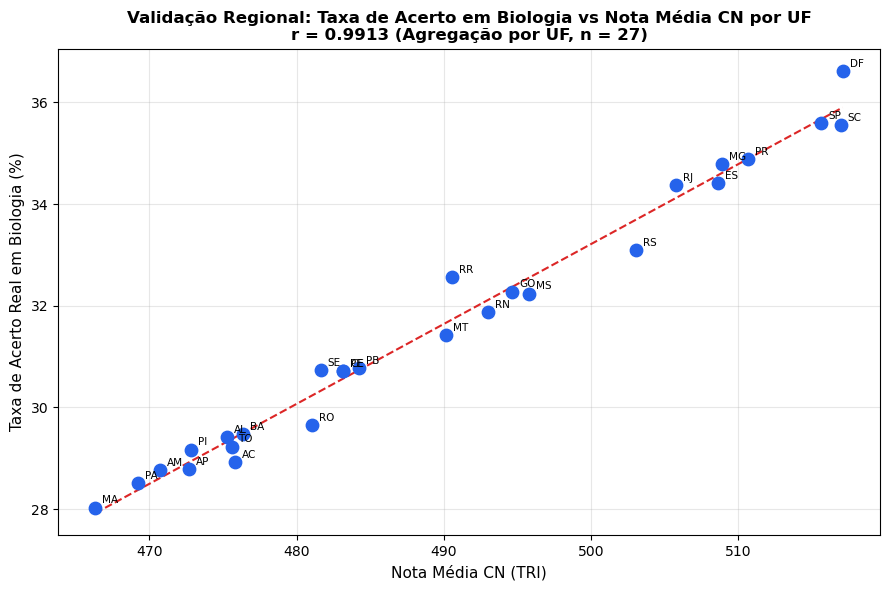

✔ Gráfico de correlação salvo.

Carregando malha do Brasil para o Mapa Real...


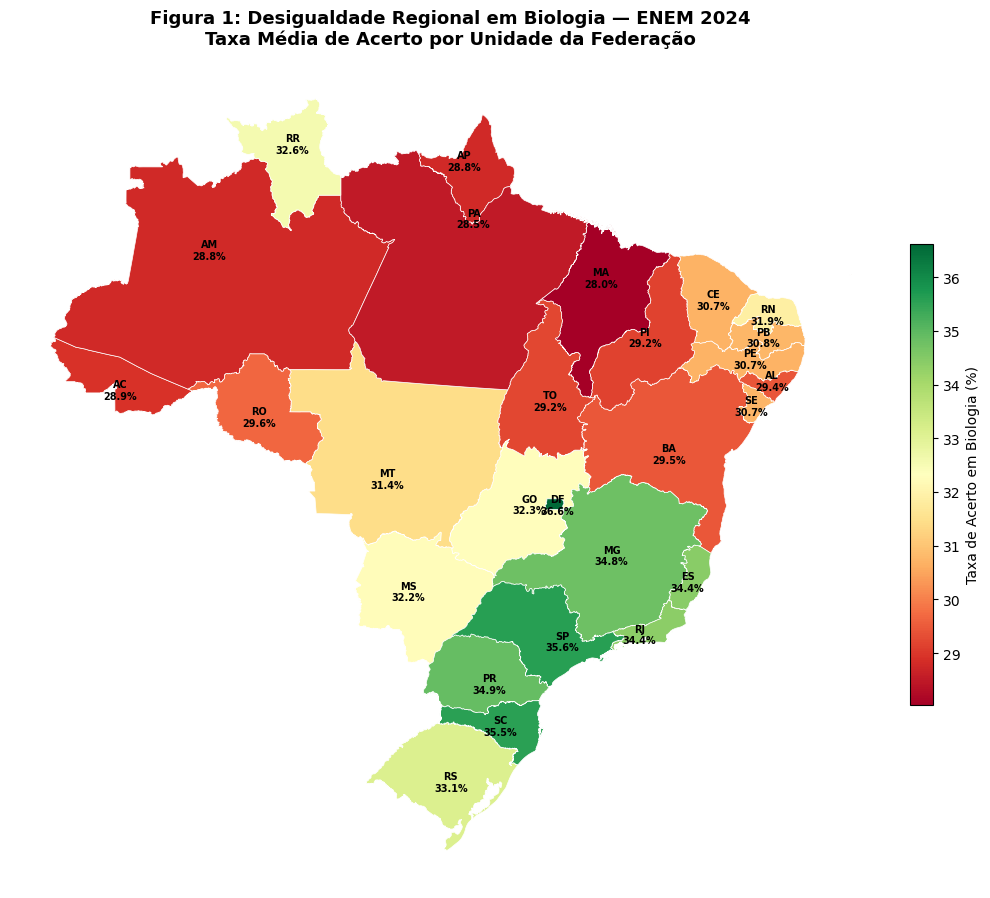

✔ Mapa real salvo.

Aprofundamento na habilidade de maior gap real (H03)...


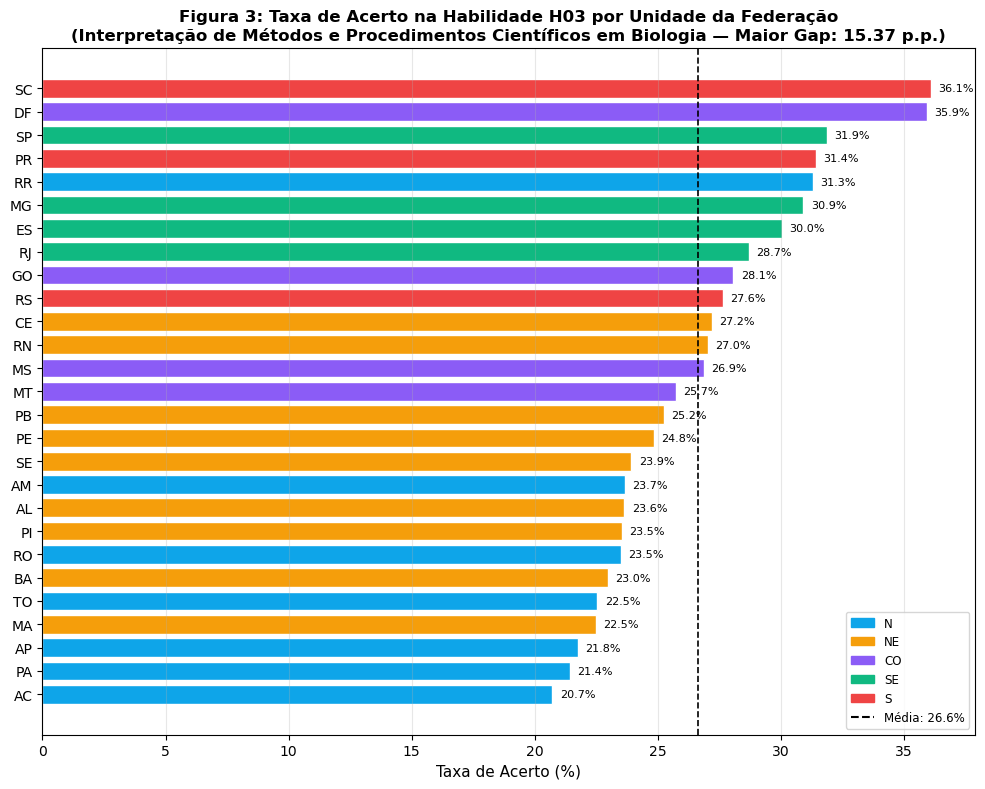


Gerando Heatmap real com as 11 habilidades de Biologia...


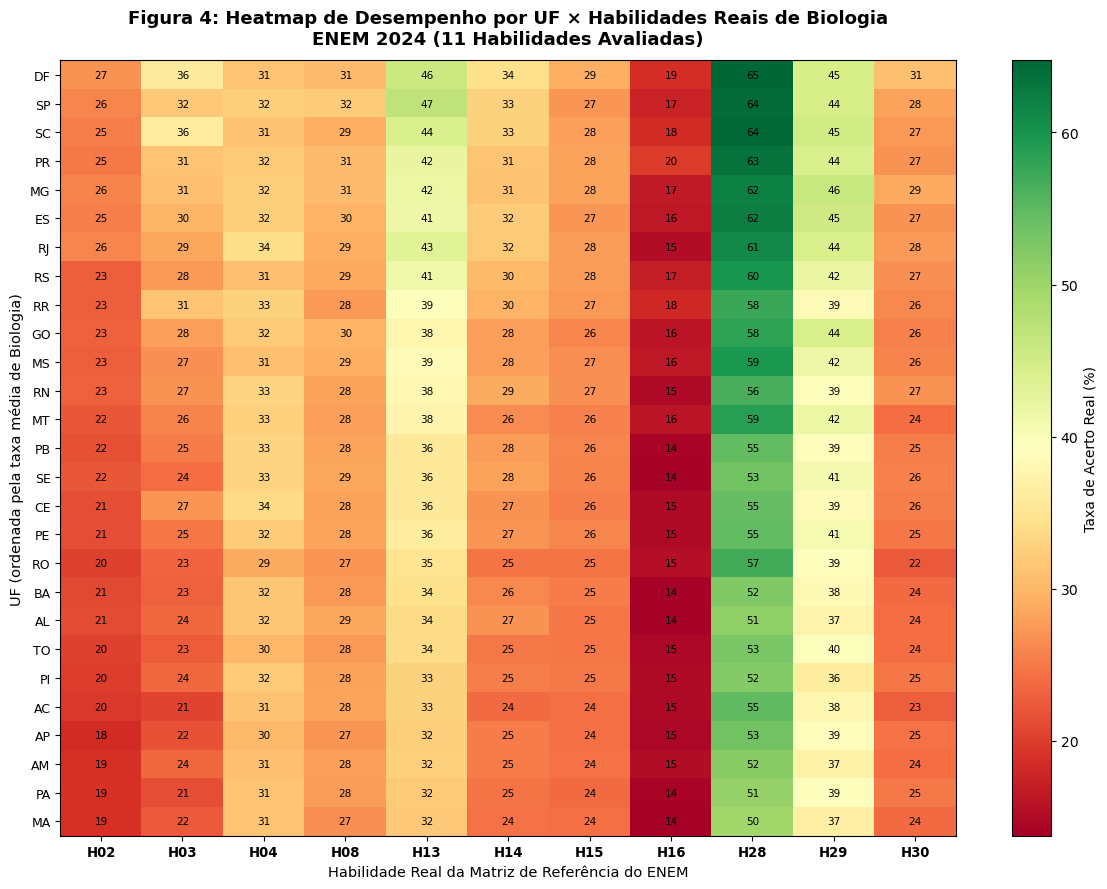


✔ Todos os gráficos reais foram gerados e salvos com sucesso em: G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS


In [9]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import json
import urllib.request

# ── CAMINHOS (GOOGLE DRIVE) ──────────────────────────────────────────────────
BASE        = r"G:\Meu Drive\2026\MICRODADOS ENEM - 2024\microdados_enem_2024\DADOS"
SAIDA_PLOTS = BASE

# ── CARREGA OS CSVS CORRIGIDOS REAIS ─────────────────────────────────────────
df_uf  = pd.read_csv(os.path.join(BASE, "acerto_biologia_por_uf_CORRIGIDO.csv"), sep=";")
df_hab = pd.read_csv(os.path.join(BASE, "acerto_biologia_por_uf_habilidade_CORRIGIDO.csv"), sep=";")
gap    = pd.read_csv(os.path.join(BASE, "gap_regional_habilidades_biologia_CORRIGIDO.csv"), sep=";")

# ════════════════════════════════════════════════════════════════════════════
# PASSO 1 — VALIDAÇÃO: taxa de acerto real vs nota média CN por UF
# ════════════════════════════════════════════════════════════════════════════
print("Analisando covariância entre taxa real de Biologia e nota média de CN...")

# Como nota_media_cn já foi calculada no passo anterior, não precisamos reler o CSV bruto
df_val = df_uf[["SG_UF_PROVA", "taxa_acerto", "nota_media_cn"]].dropna().copy()
corr   = df_val["taxa_acerto"].corr(df_val["nota_media_cn"])

print(f"\nCorrelação real Biologia × Nota Média CN: r = {corr:.4f} (n = {len(df_val)})")
print(df_val.sort_values("nota_media_cn", ascending=False).to_string(index=False))

# Scatter Plot de validação
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df_val["nota_media_cn"], df_val["taxa_acerto"], s=80, color="#2563EB", zorder=3)

for _, row in df_val.iterrows():
    ax.annotate(row["SG_UF_PROVA"],
                (row["nota_media_cn"], row["taxa_acerto"]),
                textcoords="offset points", xytext=(5, 3), fontsize=7.5)

m, b = np.polyfit(df_val["nota_media_cn"], df_val["taxa_acerto"], 1)
xs   = np.linspace(df_val["nota_media_cn"].min(), df_val["nota_media_cn"].max(), 100)
ax.plot(xs, m*xs + b, color="#DC2626", linewidth=1.5, linestyle="--")

ax.set_xlabel("Nota Média CN (TRI)", fontsize=11)
ax.set_ylabel("Taxa de Acerto Real em Biologia (%)", fontsize=11)
ax.set_title(f"Validação Regional: Taxa de Acerto em Biologia vs Nota Média CN por UF\nr = {corr:.4f} (Agregação por UF, n = 27)",
             fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAIDA_PLOTS, "validacao_acerto_vs_nota_CORRIGIDO.png"), dpi=150)
plt.show()
print("✔ Gráfico de correlação salvo.")

# ════════════════════════════════════════════════════════════════════════════
# PASSO 2 — VISUALIZAÇÃO: mapa coroplético do Brasil por UF (Biologia Real)
# ════════════════════════════════════════════════════════════════════════════
print("\nCarregando malha do Brasil para o Mapa Real...")

url_geo = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
try:
    with urllib.request.urlopen(url_geo) as resp:
        geo = json.loads(resp.read().decode())
        
    taxa_dict = df_uf.set_index("SG_UF_PROVA")["taxa_acerto"].to_dict()
    vmin, vmax = df_uf["taxa_acerto"].min(), df_uf["taxa_acerto"].max()
    cmap = plt.cm.RdYlGn
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    fig, ax = plt.subplots(figsize=(10, 11))
    ax.set_aspect("equal")
    ax.axis("off")

    for feature in geo["features"]:
        sigla = feature["properties"].get("sigla", "")
        taxa  = taxa_dict.get(sigla, None)
        cor   = cmap(norm(taxa)) if taxa is not None else (0.85, 0.85, 0.85, 1)

        geom  = feature["geometry"]
        polys = (geom["coordinates"] if geom["type"] == "Polygon" else [c for c in geom["coordinates"]])

        for poly in polys:
            coords = poly[0] if geom["type"] == "MultiPolygon" else poly
            xs_p   = [c[0] for c in coords]
            ys_p   = [c[1] for c in coords]
            ax.fill(xs_p, ys_p, color=cor, edgecolor="white", linewidth=0.5)

        all_coords = []
        for poly in polys:
            coords = poly[0] if geom["type"] == "MultiPolygon" else poly
            all_coords.extend(coords)
        cx = np.mean([c[0] for c in all_coords])
        cy = np.mean([c[1] for c in all_coords])
        
        if taxa is not None:
            ax.text(cx, cy, f"{sigla}\n{taxa:.1f}%",
                    ha="center", va="center", fontsize=7, fontweight="bold", color="black")

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("Taxa de Acerto em Biologia (%)", fontsize=10)

    ax.set_title("Figura 1: Desigualdade Regional em Biologia — ENEM 2024\nTaxa Média de Acerto por Unidade da Federação",
                 fontsize=13, fontweight="bold", pad=12)
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_PLOTS, "mapa_biologia_por_uf_CORRIGIDO.png"), dpi=150)
    plt.show()
    print("✔ Mapa real salvo.")
except Exception as e:
    print(f"Aviso ao carregar mapa online: {e}")

# ════════════════════════════════════════════════════════════════════════════
# PASSO 3 — APROFUNDAMENTO DA HABILIDADE DE MAIOR GAP REAL (H03)
# ════════════════════════════════════════════════════════════════════════════
print("\nAprofundamento na habilidade de maior gap real (H03)...")

# Na Biologia real do ENEM 2024, a habilidade com maior desigualdade é a H03 (gap = 15.37 pp)
h_maior_gap = int(gap.iloc[0]["CO_HABILIDADE"])
h_dados = df_hab[df_hab["CO_HABILIDADE"] == h_maior_gap].sort_values("taxa_acerto", ascending=True)

regioes = {
    "AC":"N","AM":"N","AP":"N","PA":"N","RO":"N","RR":"N","TO":"N",
    "AL":"NE","BA":"NE","CE":"NE","MA":"NE","PB":"NE","PE":"NE","PI":"NE","RN":"NE","SE":"NE",
    "DF":"CO","GO":"CO","MS":"CO","MT":"CO",
    "ES":"SE","MG":"SE","RJ":"SE","SP":"SE",
    "PR":"S","RS":"S","SC":"S"
}
cores_reg = {"N":"#0EA5E9", "NE":"#F59E0B", "CO":"#8B5CF6", "SE":"#10B981", "S":"#EF4444"}
cores_bar = [cores_reg.get(regioes.get(uf, ""), "#888888") for uf in h_dados["SG_UF_PROVA"]]

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(h_dados["SG_UF_PROVA"], h_dados["taxa_acerto"], color=cores_bar, edgecolor="white")
media_h = h_dados["taxa_acerto"].mean()
ax.axvline(media_h, color="black", linestyle="--", linewidth=1.2)

for bar, val in zip(bars, h_dados["taxa_acerto"]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center", fontsize=8)

legend_patches = [mpatches.Patch(color=c, label=r) for r, c in cores_reg.items()]
ax.legend(handles=legend_patches + [plt.Line2D([0], [0], color="black", linestyle="--", label=f"Média: {media_h:.1f}%")],
          fontsize=8.5, loc="lower right")

ax.set_xlabel("Taxa de Acerto (%)", fontsize=11)
ax.set_title(f"Figura 3: Taxa de Acerto na Habilidade H03 por Unidade da Federação\n(Interpretação de Métodos e Procedimentos Científicos em Biologia — Maior Gap: {gap.iloc[0]['gap']:.2f} p.p.)",
             fontsize=12, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAIDA_PLOTS, "aprofundamento_maior_gap_H03_CORRIGIDO.png"), dpi=150)
plt.show()

# ════════════════════════════════════════════════════════════════════════════
# PASSO 4 — HEATMAP REAL: UF × HABILIDADES REAIS DE BIOLOGIA (11 HABILIDADES)
# ════════════════════════════════════════════════════════════════════════════
print("\nGerando Heatmap real com as 11 habilidades de Biologia...")

pivot = df_hab.pivot(index="SG_UF_PROVA", columns="CO_HABILIDADE", values="taxa_acerto")
pivot = pivot.reindex(df_uf.sort_values("taxa_acerto", ascending=False)["SG_UF_PROVA"])
pivot.columns = [f"H{int(c):02d}" for c in pivot.columns]

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(pivot.values, cmap="RdYlGn", aspect="auto",
               vmin=pivot.values.min(), vmax=pivot.values.max())

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=9.5, fontweight="bold")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=9)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=7.5, color="black")

plt.colorbar(im, ax=ax, label="Taxa de Acerto Real (%)")
ax.set_title("Figura 4: Heatmap de Desempenho por UF × Habilidades Reais de Biologia\nENEM 2024 (11 Habilidades Avaliadas)",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Habilidade Real da Matriz de Referência do ENEM", fontsize=10.5)
ax.set_ylabel("UF (ordenada pela taxa média de Biologia)", fontsize=10.5)
plt.tight_layout()
plt.savefig(os.path.join(SAIDA_PLOTS, "heatmap_biologia_uf_habilidade_CORRIGIDO.png"), dpi=150)
plt.show()

print("\n✔ Todos os gráficos reais foram gerados e salvos com sucesso em:", SAIDA_PLOTS)

 ### Análise completa:

1. Validação da Covariância Regional ($r = 0,9913, n = 27$)Achado:  Há uma forte covariância linear positiva ($r = 0,9913$) entre o percentual médio de acertos nas 15 questões de Biologia e a proficiência média em Ciências da Natureza (escala TRI) agregadas por UF.   Interpretação Científica: Esse coeficiente de 0,99 decorre do efeito de agregação ecológica sobre as 27 UFs e do fato de a Biologia compor 1/3 dos itens de CN. Ele evidencia que as disparidades regionais no aprendizado biológico caminham pari passu com o desempenho global da área científica, sem a pretensão equivocada de "validar o instrumento psicométrico do Inep".   
2. Distribuição Espacial e Desempenho Geral por UFAmplitude Geral:  O rendimento médio em Biologia no Brasil variou 8,59 p.p., partindo de 28,03% no Maranhão (MA) até 36,62% no Distrito Federal (DF).   Padrão Territorial:O grupo de melhor desempenho é liderado pelo DF (36,62%), seguido por SP (35,59%), SC (35,55%), PR (34,88%), MG (34,78%), ES (34,41%) e RJ (34,38%). O RS aparece ligeiramente descolado do Sul/Sudeste com 33,10%. As menores médias concentram-se no eixo Norte-Nordeste: MA (28,03%), PA (28,52%), AM (28,77%), AP (28,79%), AC (28,92%), PI (29,17%), TO (29,23%), AL (29,41%) e BA (29,47%).   
3. O Maior Gap Regional da Disciplina: H03 (Figura 3)Achado Real: A maior desigualdade geográfica da Biologia ocorre na Habilidade H03 (Interpretação e avaliação de métodos, hipóteses e procedimentos em experimentos científicos), com uma amplitude de 15,37 p.p..   Extremos: Santa Catarina obteve o melhor resultado com 36,1%, enquanto o Acre registrou 20,7% (a média nacional da habilidade ficou em 26,6%).   Interpretação: Esse dado derruba a tese anterior de que Ecologia causava um abismo de 20 p.p. O que mais divide o país no ensino de Biologia é a capacidade de interpretar o método científico e experimentos laboratoriais, competência muito dependente de infraestrutura e formação docente.   Outros Gaps Relevantes: H13 (Cadeias tróficas e fluxo de matéria/energia) e H28 (Genética clássica e biotecnologia) também apresentaram gaps expressivos de 15,11 p.p.   
4. Heatmap Curricular: 11 Habilidades Reais de Biologia (Figura 4)O mapeamento das 11 habilidades por UF evidencia três comportamentos didáticos nítidos:   Gargalo Crítico Abaixo do Acaso — H16:A habilidade H16 (Saúde pública, indicadores sanitários, medidas de imunização e profilaxia) teve médias de 14% a 20% em todo o Brasil (tonalidade vermelho escuro generalizada). Em praticamente todos os estados, a taxa ficou no piso ou abaixo do chute aleatório (20%). Isso revela uma gravíssima deficiência pedagógica e de transposição didática nacional sobre imunologia e epidemiologia.   Gargalo Conceitual Estrutural — H02 e H15:H02 (Metabolismo celular, bioenergética e bioquímica) permaneceu em patamares baixos em todas as regiões (18% a 27%), com variação regional mínima. H15 (Ecologia de populações e relações ecológicas) variou apenas entre 24% e 29% (gap de apenas 5,49 p.p.). São conteúdos complexos que constituem "desafios estruturais da matriz", onde mesmo os estados com mais recursos não conseguem atingir proficiência satisfatória.   Consolidação Didática — H28 e H13: Em contrapartida, H28 (Genética e biotecnologia) foi a habilidade com maior taxa de acerto do exame, variando de 50% no MA a 65% no DF (tons verdes predominantes).H13 (Ecologia básica / teias tróficas) também manteve bom rendimento geral, entre 32% e 47%.